# Lab 3: Clustering Analysis Using K-Means and K-Medoids Algorithms
**Student:** Bharath Kumar Origanti  
**Course:** Advanced Big Data and Data Mining (MSCS-634)  
**Dataset:** scikit-learn Wine dataset

This notebook explores, standardizes, clusters, evaluates, and visualizes the Wine dataset. It uses a reproducible random seed. K-Medoids is implemented directly so no optional third-party package is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances
from sklearn.decomposition import PCA

RANDOM_STATE = 42
wine = load_wine()
X = wine.data
y = wine.target
features = wine.feature_names
frame = pd.DataFrame(X, columns=features)
frame['wine_class'] = y
print('Dataset dimensions:', X.shape)
print('Feature names:', features)
print('Class distribution:')
print(frame['wine_class'].value_counts().sort_index().to_string())
display(frame.head())
display(frame[features].describe().round(2))

Dataset dimensions: (178, 13)
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Class distribution:
wine_class
0    59
1    71
2    48


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


## Prepare the dataset
The original chemical measurements have different scales. StandardScaler performs z-score normalization before distance-based clustering. True wine class labels are used **only for evaluation**, not for fitting the clusters.

In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Scaled feature means (approximately zero):', np.round(X_scaled.mean(axis=0), 3))
print('Scaled feature standard deviations (approximately one):', np.round(X_scaled.std(axis=0), 3))

Scaled feature means (approximately zero): [ 0.  0. -0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]
Scaled feature standard deviations (approximately one): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## K-Means (k = 3)
K-Means minimizes the sum of squared distances between observations and cluster centroids. We calculate Silhouette Score (internal cluster separation) and Adjusted Rand Index (agreement with known wine classes).

In [3]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=20)
kmeans_labels = kmeans.fit_predict(X_scaled)
km_sil = silhouette_score(X_scaled, kmeans_labels)
km_ari = adjusted_rand_score(y, kmeans_labels)
print(f'K-Means Silhouette Score: {km_sil:.4f}')
print(f'K-Means Adjusted Rand Index: {km_ari:.4f}')
print('Cluster sizes:', np.bincount(kmeans_labels))

K-Means Silhouette Score: 0.2849
K-Means Adjusted Rand Index: 0.8975
Cluster sizes: [65 51 62]


## K-Medoids (k = 3)
A medoid is an actual observed sample, unlike a K-Means centroid. The implementation below initializes distinct medoids, assigns samples to their closest medoid using Euclidean distance, and iteratively swaps a medoid with a non-medoid when the swap reduces total distance. This is a straightforward PAM-style swap optimization suitable for this small dataset.

In [4]:
def fit_kmedoids(X, k=3, random_state=42, max_iter=100):
    rng = np.random.default_rng(random_state)
    distances = pairwise_distances(X, metric='euclidean')
    n_samples = len(X)
    medoids = np.sort(rng.choice(n_samples, size=k, replace=False))

    def total_cost(indices):
        return distances[:, indices].min(axis=1).sum()

    cost = total_cost(medoids)
    for iteration in range(max_iter):
        best_cost, best_medoids = cost, medoids
        candidates = np.setdiff1d(np.arange(n_samples), medoids)
        for pos in range(k):
            for candidate in candidates:
                trial = medoids.copy()
                trial[pos] = candidate
                trial_cost = total_cost(trial)
                if trial_cost < best_cost - 1e-10:
                    best_cost, best_medoids = trial_cost, trial.copy()
        if best_cost >= cost - 1e-10:
            break
        medoids, cost = best_medoids, best_cost
    labels = distances[:, medoids].argmin(axis=1)
    return labels, medoids, cost, iteration + 1

kmedoids_labels, medoid_indices, medoid_cost, iterations = fit_kmedoids(X_scaled, k=3, random_state=RANDOM_STATE)
medoid_points = X_scaled[medoid_indices]
med_sil = silhouette_score(X_scaled, kmedoids_labels)
med_ari = adjusted_rand_score(y, kmedoids_labels)
print('Medoid sample indices:', medoid_indices)
print('Iterations:', iterations)
print('Total within-cluster Euclidean distance:', round(medoid_cost, 3))
print(f'K-Medoids Silhouette Score: {med_sil:.4f}')
print(f'K-Medoids Adjusted Rand Index: {med_ari:.4f}')
print('Cluster sizes:', np.bincount(kmedoids_labels))

Medoid sample indices: [ 35 106 148]
Iterations: 4
Total within-cluster Euclidean distance: 500.929
K-Medoids Silhouette Score: 0.2676
K-Medoids Adjusted Rand Index: 0.7411
Cluster sizes: [74 55 49]


## Compare the performance metrics
A larger Silhouette Score suggests tighter, better-separated clusters. ARI measures agreement with the actual wine categories and is adjusted for chance. Because these methods optimize different objectives, their metrics need not favor the same algorithm.

In [5]:
results = pd.DataFrame({
    'Algorithm': ['K-Means', 'K-Medoids'],
    'Silhouette Score': [km_sil, med_sil],
    'Adjusted Rand Index (ARI)': [km_ari, med_ari]
})
display(results.round(4))
print('Higher Silhouette Score:', results.loc[results['Silhouette Score'].idxmax(), 'Algorithm'])
print('Higher ARI:', results.loc[results['Adjusted Rand Index (ARI)'].idxmax(), 'Algorithm'])

,Algorithm,Silhouette Score,Adjusted Rand Index (ARI)
0,K-Means,0.2849,0.8975
1,K-Medoids,0.2676,0.7411


Higher Silhouette Score: K-Means
Higher ARI: K-Means


## Side-by-side visualization
PCA projects the 13 standardized features into two dimensions for plotting. The clustering and evaluation scores above use **all 13 features**, not the 2D projection. The centroid/medoid markers are projected into the same PCA space.

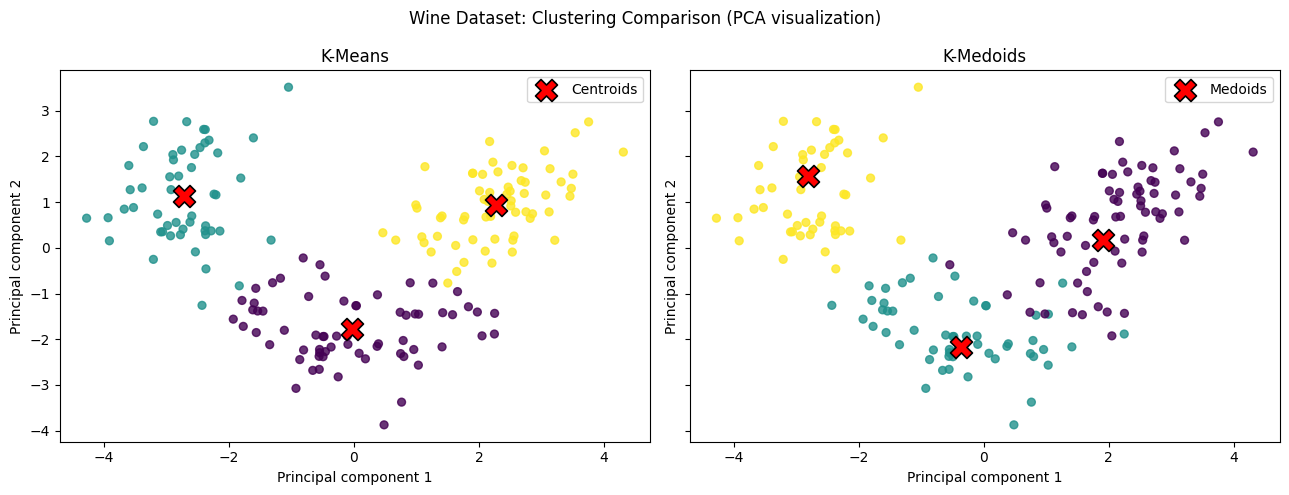

Explained variance by first two PCs: 0.5541


In [6]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
centroids_2d = pca.transform(kmeans.cluster_centers_)
medoids_2d = pca.transform(medoid_points)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, labels, centers, title, center_label in [
    (axes[0], kmeans_labels, centroids_2d, 'K-Means', 'Centroids'),
    (axes[1], kmedoids_labels, medoids_2d, 'K-Medoids', 'Medoids')
]:
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='viridis', s=32, alpha=0.8)
    ax.scatter(centers[:, 0], centers[:, 1], marker='X', s=250, c='red', edgecolors='black', linewidths=1.2, label=center_label)
    ax.set_title(title)
    ax.set_xlabel('Principal component 1')
    ax.set_ylabel('Principal component 2')
    ax.legend()
fig.suptitle('Wine Dataset: Clustering Comparison (PCA visualization)')
fig.tight_layout()
fig.savefig('clustering_comparison.png', dpi=170, bbox_inches='tight')
plt.show()
print('Explained variance by first two PCs:', round(pca.explained_variance_ratio_.sum(), 4))

## Findings and interpretation

In [7]:
print(f'K-Means: silhouette={km_sil:.4f}, ARI={km_ari:.4f}')
print(f'K-Medoids: silhouette={med_sil:.4f}, ARI={med_ari:.4f}')
print('Silhouette winner:', 'K-Means' if km_sil > med_sil else 'K-Medoids' if med_sil > km_sil else 'Tie')
print('ARI winner:', 'K-Means' if km_ari > med_ari else 'K-Medoids' if med_ari > km_ari else 'Tie')

K-Means: silhouette=0.2849, ARI=0.8975
K-Medoids: silhouette=0.2676, ARI=0.7411
Silhouette winner: K-Means
ARI winner: K-Means


**Interpretation:** Compare the two numeric metrics above and the side-by-side PCA plot. Higher Silhouette Score indicates better within-cluster cohesion and between-cluster separation; higher ARI indicates stronger alignment with the dataset’s known wine categories. Cluster IDs are arbitrary and do not directly correspond to the numeric class labels. Some overlap in the PCA plot is expected because 2D PCA discards part of the 13-dimensional information.

**Cluster shapes and positions:** K-Means centers can fall between observed wines because they are arithmetic averages; K-Medoids representatives are actual wines. Both distance-based approaches tend to favor relatively compact clusters. The precise boundaries and apparent overlaps depend on the projection and optimization result.

**When to prefer each:** K-Means is generally faster and is useful for larger numeric datasets when squared Euclidean distances and mean-based centers are appropriate. K-Medoids is useful when representative real observations are important or greater resistance to extreme observations is desirable, but the swap-based optimization used here costs more computation.

**Implementation decision / challenge:** A direct PAM-style K-Medoids implementation avoids dependency installation issues, but checks many possible swaps; this is acceptable for the 178-row Wine dataset and less suitable for very large datasets.

**Reproducibility:** Both algorithms use random seed 42. Different initializations or K-Medoids implementations can lead to different scores.

## References
- scikit-learn developers. *Wine recognition dataset*, `load_wine` documentation. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html
- scikit-learn developers. *KMeans* documentation. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
- scikit-learn developers. *Clustering performance evaluation*. https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation